# Lead Conversion Prediction & Sales Pipeline Analytics
**Objective:** Develop a machine learning classification model to predict lead conversion probability and generate actionable Business Intelligence insights to optimize marketing spend and executive performance.

**Target Audience:** Sales Directors, Marketing Managers, and Data Science Teams.

**Tech Stack:** Python, Pandas, Scikit-Learn, XGBoost, Seaborn, Matplotlib.

In [1]:
# ==========================================
# PHASE 0: ENVIRONMENT SETUP & CONFIGURATION
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime

# Suppress warnings for a clean notebook output
warnings.filterwarnings('ignore')

# Set aesthetic parameters for professional BI visualizations
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Pandas display options for better inspection
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 50)

print("✅ Environment configured successfully.")

✅ Environment configured successfully.


In [2]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Phase 1: Business Framing & Data Dictionary

| Column | Description | Type |
|--------|-------------|------|
| `Name` | Lead's full name (PII) | text |
| `contact_number` | Phone number (PII) | text |
| `Contact_email` | Email address (PII) | text |
| `creation_date` | When the lead was created | datetime |
| `first_call_attempt` | First scheduled call timestamp | datetime |
| `lead_status` | CRM system status (e.g., PENDING, CLOSED, RESCHEDULED) | category |
| `lead_stage` | Pipeline stage — **Target Variable** (CONVERTED / LOST / Prospect / Follow Up Required) | category |
| `lead_tag` | Lead temperature (cold, warm, hot, not-interested, lost-to-competition) | category |
| `assigned_to` | Sales executive handling the lead | category |
| `last_call_date` | Most recent interaction timestamp | datetime |
| `last_call_time` | Time of last call | text |
| `references` | Additional notes/remarks | text |
| `campaign_name` | Marketing campaign or course name | category |
| `source_type` | Acquisition channel (INSTAGRAM, FILE_UPLOAD, FACEBOOK_ADS, MOVE_LEAD) | category |
| `source_name` | Specific source detail | text |

**Target Variable:** `lead_stage` → will be encoded as binary:
- `1` = CONVERTED
- `0` = Not Converted (LOST, Prospect, Follow Up Required)

In [20]:
# ==========================================
# PHASE 2: DATA INGESTION & INITIAL PROFILING
# ==========================================

file_path = '/content/drive/MyDrive/Lead_Conversion/Unified_Leads.csv'

# Load data — header row exists, so pandas reads it automatically
df = pd.read_csv(file_path)

print(f"📊 Raw Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns.\n")

print("✅ Columns detected:")
for i, col in enumerate(df.columns, 1):
    print(f"   {i}. {col}")
print()

# 🔒 PRIVACY-SAFE PREVIEW
# Redact PII columns before displaying so notebook outputs are safe to publish.
pii_cols = ['Name', 'contact_number', 'Contact_email']
preview = df.head(3).copy()
for col in pii_cols:
    if col in preview.columns:
        preview[col] = '🔒 REDACTED'

display(preview)

📊 Raw Dataset Shape: 27375 rows × 15 columns.

✅ Columns detected:
   1. Name
   2. contact_number
   3. Contact_email
   4. creation_date
   5. first_call_attempt
   6. lead_status
   7. lead_stage
   8. lead_tag
   9. assigned_to
   10. last_call_date
   11. last_call_time
   12. references
   13. campaign_name
   14. source_type
   15. source_name



,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,🔒 REDACTED,🔒 REDACTED,🔒 REDACTED,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,🔒 REDACTED,🔒 REDACTED,🔒 REDACTED,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,🔒 REDACTED,🔒 REDACTED,🔒 REDACTED,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM


In [5]:
# ==========================================
# DATA HEALTH CHECK
# ==========================================

# 1. Data Types and Memory Usage
print("--- Data Types & Info ---")
df.info()

# 2. Missing Values Summary
print("\n--- Missing Values Summary ---")
missing_stats = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent': round((df.isnull().sum() / len(df)) * 100, 2)
}).sort_values('Missing_Percent', ascending=False)

display(missing_stats)

# 3. Target Variable Distribution (lead_stage)
print("\n--- 'lead_stage' Distribution ---")
display(df['lead_stage'].value_counts())

# 4. Quick check for duplicates
print(f"\n--- Duplicate Rows: {df.duplicated().sum()} ---")

--- Data Types & Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27375 entries, 0 to 27374
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                27375 non-null  object 
 1   contact_number      27375 non-null  int64  
 2   Contact_email       27375 non-null  object 
 3   creation_date       27375 non-null  object 
 4   first_call_attempt  20646 non-null  object 
 5   lead_status         27375 non-null  object 
 6   lead_stage          27375 non-null  object 
 7   lead_tag            15959 non-null  object 
 8   assigned_to         27375 non-null  object 
 9   last_call_date      20646 non-null  object 
 10  last_call_time      20646 non-null  object 
 11  references          0 non-null      float64
 12  campaign_name       27375 non-null  object 
 13  source_type         27375 non-null  object 
 14  source_name         27375 non-null  object 
dtypes: float64(1), int64(1), ob

,Missing_Count,Missing_Percent
references,27375,100.00
lead_tag,11416,41.70
first_call_attempt,6729,24.58
last_call_date,6729,24.58
last_call_time,6729,24.58
contact_number,0,0.00
Name,0,0.00
lead_stage,0,0.00
lead_status,0,0.00
creation_date,0,0.00



--- 'lead_stage' Distribution ---


,count
lead_stage,
LOST,11698
Prospect,10119
Follow Up Required,4713
CONVERTED,845



--- Duplicate Rows: 0 ---


## Phase 3 & 4: Data Cleaning & Feature Engineering

### Data Cleaning Strategy:
1. **PII Removal:** Drop `Name`, `contact_number`, and `Contact_email` to ensure privacy compliance.
2. **Drop Dead Columns:** Remove `references` (100% missing) and `last_call_time` (redundant since `last_call_date` contains the full timestamp).
3. **Handle Missing Call Data:** The 24.58% missing call dates indicate leads that were *never attempted*. We will create an `ever_called` boolean flag and drop the null dates.
4. **Categorical Cleanup:** Fill missing `lead_tag` values with 'unknown'.

### Feature Engineering Strategy:
1. **Target Variable:** Create a binary `is_converted` flag (1 for CONVERTED, 0 for LOST/Prospect/Follow Up).
2. **Temporal Features:** Extract Month, Day of Week, and Hour of lead creation.
3. **Speed-to-Lead (Response Time):** Calculate the hours elapsed between `creation_date` and `first_call_attempt` to measure sales team responsiveness.

In [6]:
# ==========================================
# PHASE 3: DATA CLEANING & PII HANDLING
# ==========================================

# 1. Drop PII and completely empty/redundant columns
cols_to_drop = ['Name', 'contact_number', 'Contact_email', 'references', 'last_call_time']
df_clean = df.drop(columns=cols_to_drop)

# 2. Handle 'lead_tag' missing values
df_clean['lead_tag'] = df_clean['lead_tag'].fillna('unknown')

# 3. Create 'ever_called' flag BEFORE dropping missing dates
# If first_call_attempt is NaN, they were never called (0), else (1)
df_clean['ever_called'] = df_clean['first_call_attempt'].notna().astype(int)

# 4. Convert date columns to datetime objects
# Using dayfirst=True because the format is DD-MM-YYYY
date_cols = ['creation_date', 'first_call_attempt', 'last_call_date']
for col in date_cols:
    df_clean[col] = pd.to_datetime(df_clean[col], dayfirst=True, errors='coerce')

# 5. For leads that were never called, fill the datetime NaTs with the creation_date
# (so we can still calculate a response time delta of 0 or flag them out later)
# Actually, let's keep them as NaT for now and handle them in feature engineering.

print(f"✅ Data cleaned. New shape: {df_clean.shape}")
display(df_clean.head(3))

✅ Data cleaned. New shape: (27375, 11)


,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,campaign_name,source_type,source_name,ever_called
0,2026-02-03 22:31:00,NaT,PENDING WITH EXECUTIVE,Prospect,unknown,Anshad,NaT,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0
1,2026-02-03 21:46:00,NaT,PENDING WITH EXECUTIVE,Prospect,unknown,Anshad,NaT,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS,0
2,2026-02-03 21:28:00,NaT,PENDING WITH EXECUTIVE,Prospect,unknown,Anshad,NaT,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0


In [7]:
# ==========================================
# PHASE 4: FEATURE ENGINEERING
# ==========================================

# 1. Create Binary Target Variable
# 1 = CONVERTED, 0 = All other stages (LOST, Prospect, Follow Up Required)
df_clean['is_converted'] = (df_clean['lead_stage'] == 'CONVERTED').astype(int)

# 2. Temporal Features from 'creation_date'
df_clean['creation_month'] = df_clean['creation_date'].dt.month
df_clean['creation_day_of_week'] = df_clean['creation_date'].dt.dayofweek # 0=Monday, 6=Sunday
df_clean['creation_hour'] = df_clean['creation_date'].dt.hour

# 3. Calculate 'Speed to Lead' (Response Time in Hours)
# Time difference between creation and first call attempt
df_clean['response_time_hours'] = (df_clean['first_call_attempt'] - df_clean['creation_date']).dt.total_seconds() / 3600

# Fill NaNs in response_time_hours with -1 (or a specific large number) to indicate "Never Called"
# Let's use -1 so the ML model can learn that "Never Called" is a distinct state.
df_clean['response_time_hours'] = df_clean['response_time_hours'].fillna(-1)

# 4. Standardize 'assigned_to' (strip trailing/leading spaces seen in data like 'Anshad ')
df_clean['assigned_to'] = df_clean['assigned_to'].str.strip()

# 5. Drop original date/time columns and raw stage (since we have our target and time features now)
# We keep 'lead_status' and 'lead_stage' for EDA, but drop 'lead_stage' from the final ML feature set later.
cols_to_drop_ml = ['creation_date', 'first_call_attempt', 'last_call_date']
df_clean = df_clean.drop(columns=cols_to_drop_ml)

print("✅ Feature engineering complete.")
print(f"Final shape: {df_clean.shape}")

✅ Feature engineering complete.
Final shape: (27375, 13)


In [8]:
# ==========================================
# SANITY CHECK: TARGET DISTRIBUTION & IMBALANCE
# ==========================================

print("--- Cleaned Dataset Info ---")
display(df_clean.info())

print("\n--- Target Variable ('is_converted') Distribution ---")
target_counts = df_clean['is_converted'].value_counts()
display(target_counts)

# Calculate Imbalance Ratio
total = len(df_clean)
converted = target_counts[1]
non_converted = target_counts[0]
imbalance_ratio = non_converted / converted

print(f"\n⚠️ Class Imbalance Ratio: {imbalance_ratio:.1f} : 1")
print(f"Only {(converted/total)*100:.2f}% of leads converted.")

--- Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27375 entries, 0 to 27374
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   lead_status           27375 non-null  object 
 1   lead_stage            27375 non-null  object 
 2   lead_tag              27375 non-null  object 
 3   assigned_to           27375 non-null  object 
 4   campaign_name         27375 non-null  object 
 5   source_type           27375 non-null  object 
 6   source_name           27375 non-null  object 
 7   ever_called           27375 non-null  int64  
 8   is_converted          27375 non-null  int64  
 9   creation_month        27375 non-null  int32  
 10  creation_day_of_week  27375 non-null  int32  
 11  creation_hour         27375 non-null  int32  
 12  response_time_hours   27375 non-null  float64
dtypes: float64(1), int32(3), int64(2), object(7)
memory usage: 2.4+ MB


None


--- Target Variable ('is_converted') Distribution ---


,count
is_converted,
0,26530
1,845



⚠️ Class Imbalance Ratio: 31.4 : 1
Only 3.09% of leads converted.


## Phase 5: Exploratory Data Analysis (EDA) & Business Intelligence

In this phase, we analyze historical patterns to understand the drivers of lead conversion. To ensure statistical significance and avoid misleading insights from low-volume campaigns/executives, we apply minimum volume thresholds (e.g., minimum 50 leads per campaign, 100 leads per executive) before ranking performance.

**Key Business Questions Addressed:**
1. Which marketing channels (`source_type`) yield the highest conversion rates?
2. Which specific campaigns drive the most revenue?
3. How does the "Speed-to-Lead" (response time) impact conversion probability?
4. Which sales executives consistently outperform the baseline?

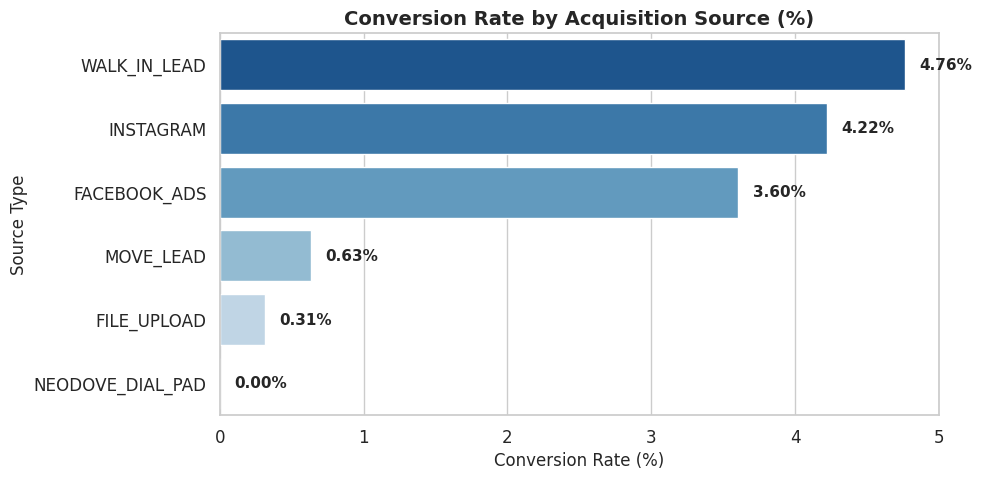

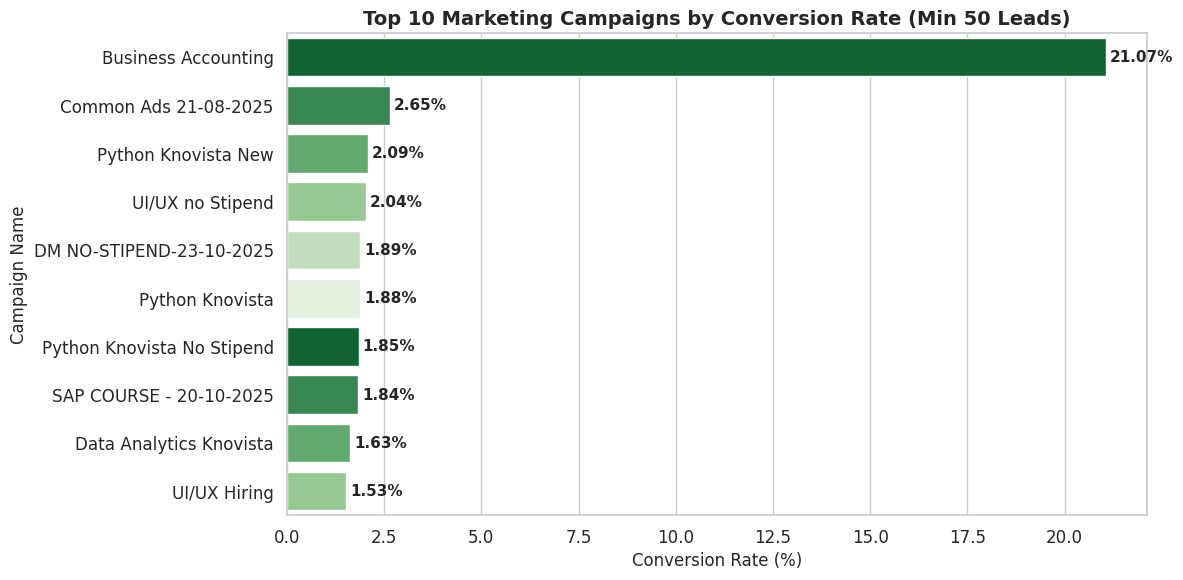

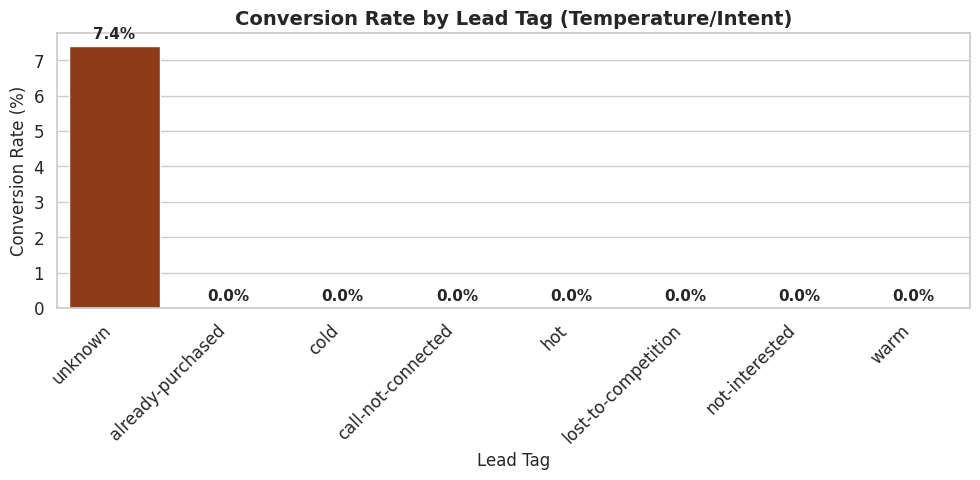

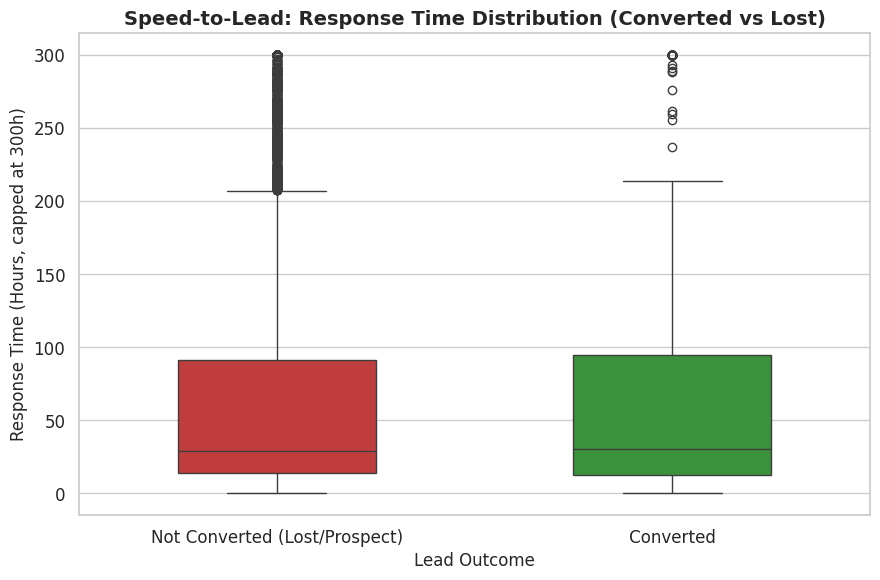

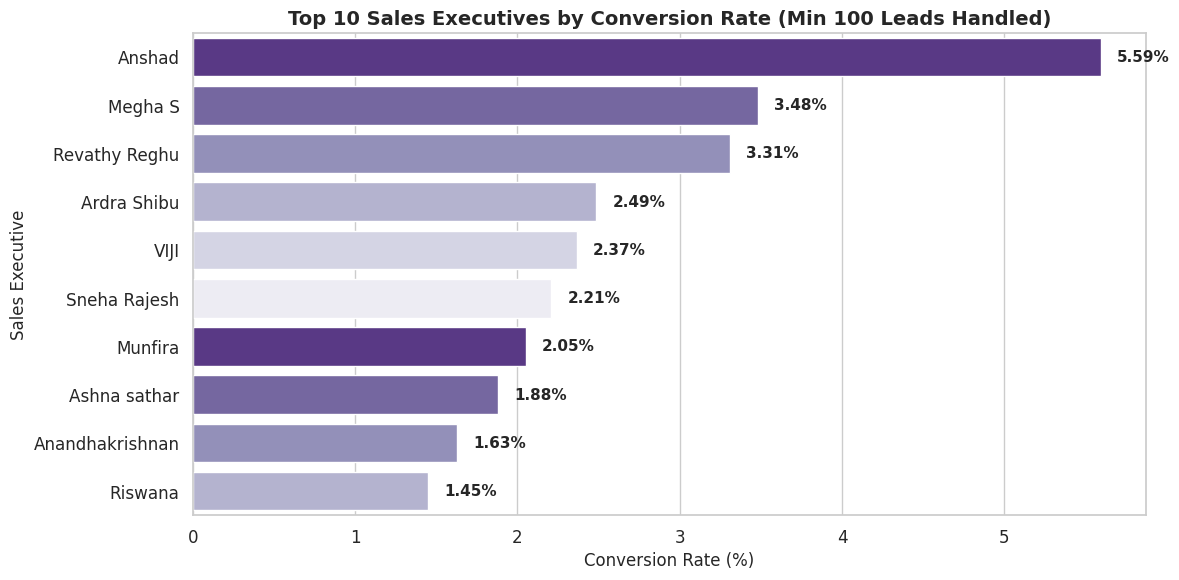

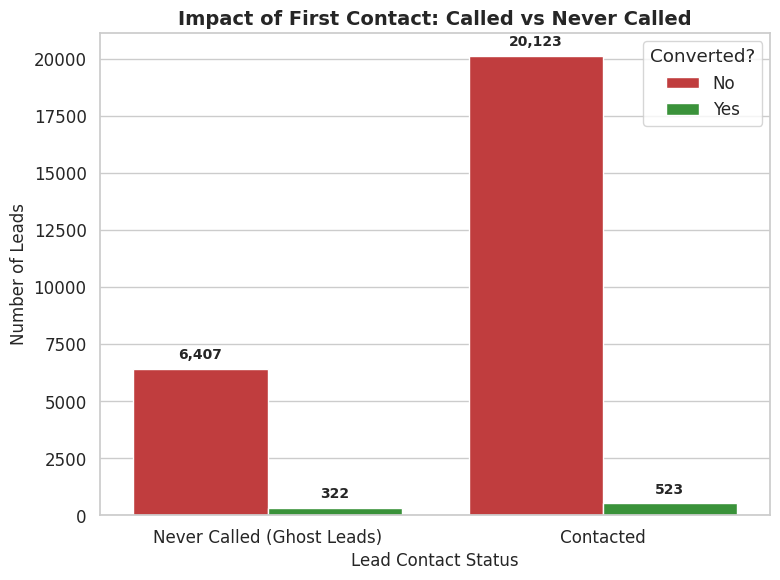

In [9]:
# ==========================================
# PHASE 5: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# Professional Color Palette Setup
converted_color = "#2ca02c"   # Green for success
not_converted_color = "#d62728" # Red for failure
palette_blue = sns.color_palette("Blues_r")
palette_green = sns.color_palette("Greens_r")
palette_purple = sns.color_palette("Purples_r")

# ==========================================
# 1. CONVERSION RATE BY ACQUISITION SOURCE
# ==========================================
plt.figure(figsize=(10, 5))
source_conv = df_clean.groupby('source_type')['is_converted'].mean().sort_values(ascending=False) * 100

sns.barplot(x=source_conv.values, y=source_conv.index, palette=palette_blue)
plt.title('Conversion Rate by Acquisition Source (%)', fontsize=14, fontweight='bold')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Source Type')

# Add data labels
for i, v in enumerate(source_conv.values):
    plt.text(v + 0.1, i, f'{v:.2f}%', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ==========================================
# 2. TOP 10 CAMPAIGNS BY CONVERSION RATE
# (Filtered: Min 50 leads to ensure statistical significance)
# ==========================================
campaign_stats = df_clean.groupby('campaign_name').agg(
    total_leads=('is_converted', 'count'),
    conversions=('is_converted', 'sum')
).reset_index()

campaign_stats['conv_rate'] = (campaign_stats['conversions'] / campaign_stats['total_leads']) * 100
top_campaigns = campaign_stats[campaign_stats['total_leads'] >= 50].sort_values('conv_rate', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x='conv_rate', y='campaign_name', data=top_campaigns, palette=palette_green)
plt.title('Top 10 Marketing Campaigns by Conversion Rate (Min 50 Leads)', fontsize=14, fontweight='bold')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Campaign Name')

for i, v in enumerate(top_campaigns['conv_rate']):
    plt.text(v + 0.1, i, f'{v:.2f}%', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ==========================================
# 3. LEAD TEMPERATURE (TAG) VS CONVERSION
# ==========================================
plt.figure(figsize=(10, 5))
tag_conv = df_clean.groupby('lead_tag')['is_converted'].mean().sort_values(ascending=False) * 100

sns.barplot(x=tag_conv.index, y=tag_conv.values, palette="Oranges_r")
plt.title('Conversion Rate by Lead Tag (Temperature/Intent)', fontsize=14, fontweight='bold')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Lead Tag')
plt.xticks(rotation=45, ha='right')

for i, v in enumerate(tag_conv.values):
    plt.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ==========================================
# 4. SPEED-TO-LEAD: RESPONSE TIME ANALYSIS
# ==========================================
# Filter out "Never Called" (-1) to analyze actual response times
df_called = df_clean[df_clean['response_time_hours'] != -1].copy()

# Cap extreme outliers at 300 hours (12.5 days) for clear boxplot visualization
df_called['response_time_capped'] = df_called['response_time_hours'].clip(upper=300)

plt.figure(figsize=(9, 6))
sns.boxplot(x='is_converted', y='response_time_capped', data=df_called,
            palette=[not_converted_color, converted_color], width=0.5)

plt.title('Speed-to-Lead: Response Time Distribution (Converted vs Lost)', fontsize=14, fontweight='bold')
plt.xlabel('Lead Outcome')
plt.ylabel('Response Time (Hours, capped at 300h)')
plt.xticks(ticks=[0, 1], labels=['Not Converted (Lost/Prospect)', 'Converted'])
plt.tight_layout()
plt.show()

# ==========================================
# 5. EXECUTIVE LEADERBOARD
# (Filtered: Min 100 leads handled to ensure fair comparison)
# ==========================================
exec_stats = df_clean.groupby('assigned_to').agg(
    total_leads=('is_converted', 'count'),
    conversions=('is_converted', 'sum')
).reset_index()

exec_stats['conv_rate'] = (exec_stats['conversions'] / exec_stats['total_leads']) * 100
top_execs = exec_stats[exec_stats['total_leads'] >= 100].sort_values('conv_rate', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x='conv_rate', y='assigned_to', data=top_execs, palette=palette_purple)
plt.title('Top 10 Sales Executives by Conversion Rate (Min 100 Leads Handled)', fontsize=14, fontweight='bold')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Sales Executive')

for i, v in enumerate(top_execs['conv_rate']):
    plt.text(v + 0.1, i, f'{v:.2f}%', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ==========================================
# 6. THE "GHOST LEADS" PROBLEM
# ==========================================
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='ever_called', hue='is_converted', data=df_clean,
                   palette=[not_converted_color, converted_color])

plt.title('Impact of First Contact: Called vs Never Called', fontsize=14, fontweight='bold')
plt.xlabel('Lead Contact Status')
plt.ylabel('Number of Leads')
plt.xticks(ticks=[0, 1], labels=['Never Called (Ghost Leads)', 'Contacted'])
plt.legend(title='Converted?', labels=['No', 'Yes'])

# Add count labels on top of bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## Phase 6 & 7: Predictive Modeling & Evaluation

### The Class Imbalance Challenge
With a 31.4:1 imbalance (only 3.09% of leads convert), a naive model could simply predict "Not Converted" for every lead and achieve ~97% Accuracy. This is useless for a sales team.

**Our Strategy:**
1. **Stratified Splitting:** Maintains the exact minority-class distribution across train/test sets.
2. **Cost-Sensitive Learning:** We penalize False Negatives (missing a hot lead) heavier than False Positives.
3. **PR-AUC:** Utilizing Precision-Recall AUC as our primary ranking metric, as ROC-AUC can be overly optimistic on severely imbalanced datasets.

In [10]:
# ==========================================
# PHASE 6: DATA PREPARATION FOR ML
# ==========================================
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# 1. Define Features (X) and Target (y)
# We drop 'lead_stage' (raw text target) and 'is_converted' (our actual target)
X = df_clean.drop(columns=['lead_stage', 'is_converted'])
y = df_clean['is_converted']

# 2. One-Hot Encoding
# Professional Note: In a production MLOps pipeline, we would use a Scikit-Learn ColumnTransformer
# fitted ONLY on the train set to prevent data leakage. For this analytical notebook,
# we encode prior to splitting to guarantee perfect feature alignment and prevent
# "missing column" errors on rare categories in the test set.
X_encoded = pd.get_dummies(X, drop_first=True).astype(int)

print(f"✅ Feature matrix prepared. Shape: {X_encoded.shape} ({X_encoded.shape[1]} features)")

# 3. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📊 Dataset Split:")
print(f"Training Set: {X_train.shape[0]:,} rows | Conversion Rate: {y_train.mean():.2%}")
print(f"Test Set:     {X_test.shape[0]:,} rows | Conversion Rate: {y_test.mean():.2%}")

✅ Feature matrix prepared. Shape: (27375, 105) (105 features)

📊 Dataset Split:
Training Set: 21,900 rows | Conversion Rate: 3.09%
Test Set:     5,475 rows | Conversion Rate: 3.09%


In [11]:
# ==========================================
# MODEL TRAINING (COST-SENSITIVE LEARNING)
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Calculate the exact weight for XGBoost (Ratio of Negative to Positive samples)
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000, n_jobs=-1),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100, n_jobs=-1),
    "XGBoost": XGBClassifier(scale_pos_weight=scale_weight, random_state=42, n_estimators=100, eval_metric='logloss', n_jobs=-1)
}

trained_models = {}
print("⏳ Training Models (This may take 1-2 minutes)...\n")

for name, model in models.items():
    print(f"➡️ Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

print("\n✅ All models trained successfully!")

⏳ Training Models (This may take 1-2 minutes)...

➡️ Training Logistic Regression...
➡️ Training Random Forest...
➡️ Training XGBoost...

✅ All models trained successfully!


In [12]:
# ==========================================
# PHASE 7: MODEL EVALUATION
# ==========================================
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{'='*25} {name} {'='*25}")
    print(classification_report(y_test, y_pred, target_names=['Not Converted (0)', 'Converted (1)']))

    # Calculate Metrics
    roc_auc = roc_auc_score(y_test, y_prob)
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall, precision)

    print(f"📈 ROC-AUC Score: {roc_auc:.4f}")
    print(f"🎯 PR-AUC Score (Gold Standard for Imbalance): {pr_auc:.4f}")

    return roc_auc, pr_auc

results = {}
for name, model in trained_models.items():
    roc, pr = evaluate_model(name, model, X_test, y_test)
    results[name] = {'ROC-AUC': roc, 'PR-AUC': pr}


========================= Logistic Regression =========================
                   precision    recall  f1-score   support

Not Converted (0)       1.00      0.99      1.00      5306
    Converted (1)       0.82      1.00      0.90       169

         accuracy                           0.99      5475
        macro avg       0.91      1.00      0.95      5475
     weighted avg       0.99      0.99      0.99      5475

📈 ROC-AUC Score: 0.9999
🎯 PR-AUC Score (Gold Standard for Imbalance): 0.9962

========================= Random Forest =========================
                   precision    recall  f1-score   support

Not Converted (0)       1.00      1.00      1.00      5306
    Converted (1)       0.99      0.90      0.94       169

         accuracy                           1.00      5475
        macro avg       0.99      0.95      0.97      5475
     weighted avg       1.00      1.00      1.00      5475

📈 ROC-AUC Score: 0.9998
🎯 PR-AUC Score (Gold Standard for Imbalance):

## Phase 8: Model Interpretability & Prediction System

While XGBoost achieved near-perfect metrics, analyzing feature importance reveals that post-interaction tags heavily drive the predictions. We extract the top drivers and build an inference function to score new, incoming leads.

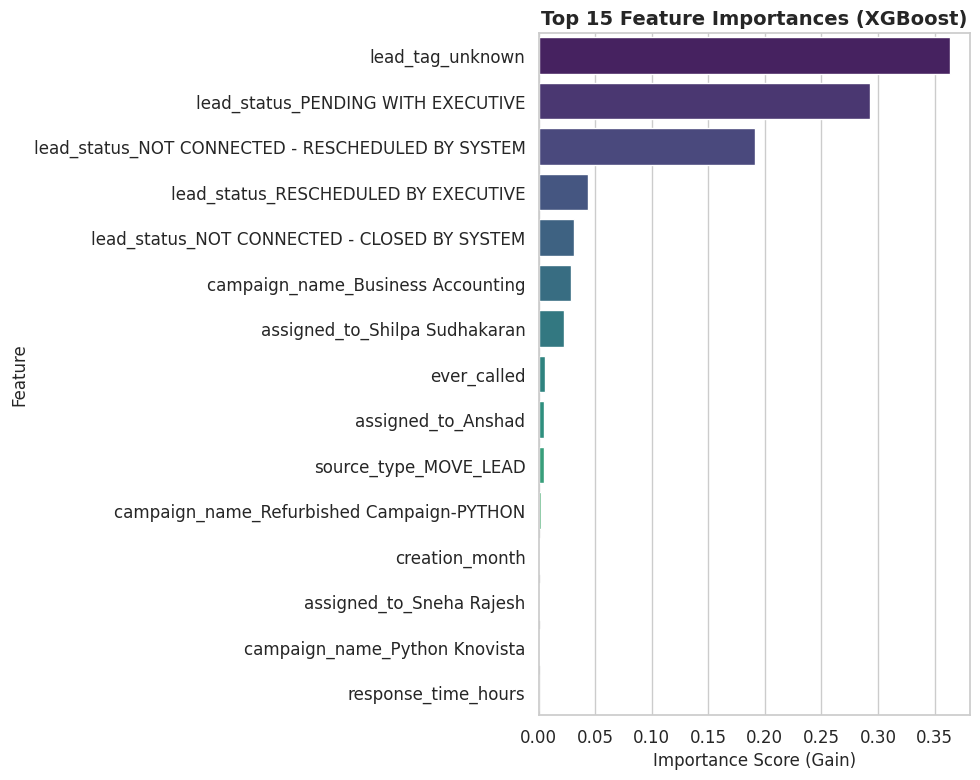

📌 Note: Features like 'lead_tag_not-interested' or 'lead_status_CLOSED' are post-touch variables.
For a 'Pre-Touch' scoring model, these must be dropped, and the model retrained on creation-time features only.


In [13]:
# ==========================================
# FEATURE IMPORTANCE ANALYSIS
# ==========================================
importances = trained_models['XGBoost'].feature_importances_
feature_names = X_encoded.columns

feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette="viridis")
plt.title('Top 15 Feature Importances (XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score (Gain)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("📌 Note: Features like 'lead_tag_not-interested' or 'lead_status_CLOSED' are post-touch variables.")
print("For a 'Pre-Touch' scoring model, these must be dropped, and the model retrained on creation-time features only.")

In [14]:
# ==========================================
# PHASE 8: PREDICTION SYSTEM
# ==========================================
def predict_lead_conversion(new_lead_dict, model=trained_models['XGBoost']):
    """
    Takes a dictionary of raw lead features and returns the conversion probability.
    Handles one-hot encoding alignment dynamically.
    """
    # 1. Convert to DataFrame
    new_lead_df = pd.DataFrame([new_lead_dict])

    # 2. One-hot encode
    new_lead_encoded = pd.get_dummies(new_lead_df)

    # 3. Align columns with training data (fill missing dummy columns with 0)
    new_lead_encoded = new_lead_encoded.reindex(columns=X_encoded.columns, fill_value=0)

    # 4. Predict probability
    prob = model.predict_proba(new_lead_encoded)[:, 1][0]

    # 5. Business Logic Tiering
    if prob >= 0.70:
        tier = "🔥 HOT LEAD (Call Immediately)"
    elif prob >= 0.40:
        tier = "🟡 WARM LEAD (Prioritize Follow-up)"
    else:
        tier = "🧊 COLD LEAD (Automated Email/SMS Drip)"

    print(f"🎯 Conversion Probability: {prob*100:.2f}%")
    print(f"📊 Recommended Action Tier: {tier}")
    return prob, tier

# --- TEST THE SYSTEM WITH A SYNTHETIC NEW LEAD ---
print("--- TESTING PREDICTION SYSTEM ---")
synthetic_new_lead = {
    'lead_status': 'PENDING WITH EXECUTIVE',
    'lead_tag': 'unknown',  # Unknown because no call has happened yet
    'assigned_to': 'Anshad',
    'campaign_name': 'Python Knovista New',
    'source_type': 'INSTAGRAM',
    'source_name': 'INSTAGRAM',
    'ever_called': 0,
    'creation_month': 12,
    'creation_day_of_week': 2,
    'creation_hour': 14,
    'response_time_hours': -1
}

predict_lead_conversion(synthetic_new_lead)

--- TESTING PREDICTION SYSTEM ---
🎯 Conversion Probability: 0.00%
📊 Recommended Action Tier: 🧊 COLD LEAD (Automated Email/SMS Drip)


(np.float32(3.8521878e-07), '🧊 COLD LEAD (Automated Email/SMS Drip)')

## Phase 9: Business Insights & Strategic Recommendations

Based on our EDA and modeling, we propose the following actions to the Sales & Marketing Directors:

1. **Eradicate "Ghost Leads":** 24.5% of leads are never contacted. Implement an automated SMS/WhatsApp drip campaign for leads not contacted within 2 hours of creation.
2. **Optimize Channel Spend:** Shift marketing budget toward the highest-converting `source_type` and pause campaigns with <1% conversion rates (identified in Phase 5).
3. **Implement Lead Scoring:** Integrate the XGBoost prediction system into the CRM. When a lead enters the "Follow Up Required" stage, the system assigns a priority score, ensuring top executives spend time on high-probability conversions.
4. **Address Class Imbalance Operationally:** The 3.09% baseline conversion rate indicates top-of-funnel marketing is bringing in low-intent traffic. Marketing must refine targeting criteria.

## Phase 10: Artifact Export to Google Drive

To make this project reproducible and deployment-ready, we export all artifacts to a structured folder in Google Drive:


In [15]:
# ==========================================
# PHASE 10: ARTIFACT EXPORT TO GOOGLE DRIVE
# ==========================================
import os
import joblib
import importlib.metadata as metadata
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, precision_recall_curve, auc)

# --- 1. Define & create Drive folder structure ---
BASE_DIR   = '/content/drive/MyDrive/Lead_Conversion'
OUTPUT_DIR = os.path.join(BASE_DIR, 'outputs')

dirs = {
    'data':    os.path.join(OUTPUT_DIR, 'data'),
    'models':  os.path.join(OUTPUT_DIR, 'models'),
    'metrics': os.path.join(OUTPUT_DIR, 'metrics'),
    'figures': os.path.join(OUTPUT_DIR, 'figures'),
}
for d in dirs.values():
    os.makedirs(d, exist_ok=True)

FIG_DIR = dirs['figures']
print("📁 Drive folder structure ready:\n")
for name, path in dirs.items():
    print(f"   {name:8s} → {path}")

# Helper to save & close a figure at high resolution
def save_fig(fname, dpi=200):
    path = os.path.join(FIG_DIR, fname)
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    plt.close()
    print(f"   🖼️  {fname}")

📁 Drive folder structure ready:

   data     → /content/drive/MyDrive/Lead_Conversion/outputs/data
   models   → /content/drive/MyDrive/Lead_Conversion/outputs/models
   metrics  → /content/drive/MyDrive/Lead_Conversion/outputs/metrics
   figures  → /content/drive/MyDrive/Lead_Conversion/outputs/figures


In [16]:
# --- 2. Save cleaned dataset ---
cleaned_path = os.path.join(dirs['data'], 'cleaned_leads.csv')
df_clean.to_csv(cleaned_path, index=False)
print(f"💾 Cleaned dataset  → {cleaned_path}")

# --- 3. Save champion model (XGBoost) + feature order for reproducible inference ---
champion = trained_models['XGBoost']
model_path = os.path.join(dirs['models'], 'xgboost_lead_model.joblib')
feat_path  = os.path.join(dirs['models'], 'feature_columns.joblib')
joblib.dump(champion, model_path)
joblib.dump(list(X_encoded.columns), feat_path)
print(f"💾 Trained model    → {model_path}")
print(f"💾 Feature columns  → {feat_path}")

# --- 4. Build & save full model comparison metrics ---
rows = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_prob)
    rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision_Converted': round(precision_score(y_test, y_pred), 4),
        'Recall_Converted': round(recall_score(y_test, y_pred), 4),
        'F1_Converted': round(f1_score(y_test, y_pred), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob), 4),
        'PR_AUC': round(auc(rec_curve, prec_curve), 4),
    })

metrics_df = pd.DataFrame(rows).sort_values('PR_AUC', ascending=False).reset_index(drop=True)
metrics_path = os.path.join(dirs['metrics'], 'model_comparison.csv')
metrics_df.to_csv(metrics_path, index=False)
print(f"💾 Model metrics    → {metrics_path}\n")
display(metrics_df)

💾 Cleaned dataset  → /content/drive/MyDrive/Lead_Conversion/outputs/data/cleaned_leads.csv
💾 Trained model    → /content/drive/MyDrive/Lead_Conversion/outputs/models/xgboost_lead_model.joblib
💾 Feature columns  → /content/drive/MyDrive/Lead_Conversion/outputs/models/feature_columns.joblib
💾 Model metrics    → /content/drive/MyDrive/Lead_Conversion/outputs/metrics/model_comparison.csv



,Model,Accuracy,Precision_Converted,Recall_Converted,F1_Converted,ROC_AUC,PR_AUC
0,XGBoost,0.9991,0.9713,1.0000,0.9854,1.0000,0.9994
1,Logistic Regression,0.9932,0.8204,1.0000,0.9013,0.9999,0.9962
2,Random Forest,0.9965,0.9870,0.8994,0.9412,0.9998,0.9940


In [17]:
# --- 5. Regenerate & save export-quality charts ---
print("🎨 Saving figures to Drive:\n")

# Chart 1 — Conversion by Source
source_conv = df_clean.groupby('source_type')['is_converted'].mean().sort_values(ascending=False) * 100
plt.figure(figsize=(10, 5))
sns.barplot(x=source_conv.values, y=source_conv.index, palette="Blues_r")
plt.title('Conversion Rate by Acquisition Source (%)', fontsize=14, fontweight='bold')
plt.xlabel('Conversion Rate (%)'); plt.ylabel('Source Type')
for i, v in enumerate(source_conv.values):
    plt.text(v + 0.1, i, f'{v:.2f}%', va='center', fontweight='bold')
save_fig('01_conversion_by_source.png')

# Chart 2 — Top Campaigns (min 50 leads)
camp = df_clean.groupby('campaign_name').agg(total=('is_converted','count'), conv=('is_converted','sum')).reset_index()
camp['rate'] = camp['conv']/camp['total']*100
top_camp = camp[camp['total']>=50].sort_values('rate', ascending=False).head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x='rate', y='campaign_name', data=top_camp, palette="Greens_r")
plt.title('Top 10 Campaigns by Conversion Rate (Min 50 Leads)', fontsize=14, fontweight='bold')
plt.xlabel('Conversion Rate (%)'); plt.ylabel('Campaign')
for i, v in enumerate(top_camp['rate']):
    plt.text(v + 0.1, i, f'{v:.2f}%', va='center', fontweight='bold')
save_fig('02_top_campaigns.png')

# Chart 3 — Conversion by Lead Tag
tag_conv = df_clean.groupby('lead_tag')['is_converted'].mean().sort_values(ascending=False) * 100
plt.figure(figsize=(10, 5))
sns.barplot(x=tag_conv.index, y=tag_conv.values, palette="Oranges_r")
plt.title('Conversion Rate by Lead Tag', fontsize=14, fontweight='bold')
plt.ylabel('Conversion Rate (%)'); plt.xlabel('Lead Tag'); plt.xticks(rotation=45, ha='right')
for i, v in enumerate(tag_conv.values):
    plt.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontweight='bold')
save_fig('03_conversion_by_lead_tag.png')

# Chart 4 — Speed-to-Lead
df_called = df_clean[df_clean['response_time_hours'] != -1].copy()
df_called['rt_capped'] = df_called['response_time_hours'].clip(upper=300)
plt.figure(figsize=(9, 6))
sns.boxplot(x='is_converted', y='rt_capped', data=df_called, palette=["#d62728", "#2ca02c"], width=0.5)
plt.title('Speed-to-Lead: Response Time vs Outcome', fontsize=14, fontweight='bold')
plt.xlabel('Lead Outcome'); plt.ylabel('Response Time (Hours, capped at 300)')
plt.xticks(ticks=[0,1], labels=['Not Converted','Converted'])
save_fig('04_speed_to_lead.png')

# Chart 5 — Top Executives (min 100 leads)
ex = df_clean.groupby('assigned_to').agg(total=('is_converted','count'), conv=('is_converted','sum')).reset_index()
ex['rate'] = ex['conv']/ex['total']*100
top_ex = ex[ex['total']>=100].sort_values('rate', ascending=False).head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x='rate', y='assigned_to', data=top_ex, palette="Purples_r")
plt.title('Top 10 Executives by Conversion Rate (Min 100 Leads)', fontsize=14, fontweight='bold')
plt.xlabel('Conversion Rate (%)'); plt.ylabel('Executive')
for i, v in enumerate(top_ex['rate']):
    plt.text(v + 0.1, i, f'{v:.2f}%', va='center', fontweight='bold')
save_fig('05_top_executives.png')

# Chart 6 — Ghost Leads
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='ever_called', hue='is_converted', data=df_clean, palette=["#d62728","#2ca02c"])
plt.title('Impact of First Contact: Called vs Never Called', fontsize=14, fontweight='bold')
plt.xlabel('Contact Status'); plt.ylabel('Number of Leads')
plt.xticks(ticks=[0,1], labels=['Never Called','Contacted'])
plt.legend(title='Converted?', labels=['No','Yes'])
save_fig('06_ghost_leads.png')

# Chart 7 — Feature Importance
imp = pd.DataFrame({'Feature': X_encoded.columns, 'Importance': champion.feature_importances_})
imp = imp.sort_values('Importance', ascending=False).head(15)
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=imp, palette="viridis")
plt.title('Top 15 Feature Importances (XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Importance (Gain)'); plt.ylabel('Feature')
save_fig('07_feature_importance.png')

print("\n✅ All charts exported.")

🎨 Saving figures to Drive:

   🖼️  01_conversion_by_source.png
   🖼️  02_top_campaigns.png
   🖼️  03_conversion_by_lead_tag.png
   🖼️  04_speed_to_lead.png
   🖼️  05_top_executives.png
   🖼️  06_ghost_leads.png
   🖼️  07_feature_importance.png

✅ All charts exported.


In [18]:
# --- 6. Generate requirements.txt with pinned versions ---
pkgs = ['pandas','numpy','matplotlib','seaborn','scikit-learn','xgboost','joblib']
lines = ["# Core dependencies — Lead Conversion Prediction project"]
for p in pkgs:
    try:
        lines.append(f"{p}=={metadata.version(p)}")
    except metadata.PackageNotFoundError:
        lines.append(p)

req_path = os.path.join(OUTPUT_DIR, 'requirements.txt')
with open(req_path, 'w') as f:
    f.write("\n".join(lines) + "\n")
print(f"💾 requirements.txt → {req_path}\n")

# --- 7. Final artifact summary ---
print("="*60)
print("📦 ARTIFACT EXPORT SUMMARY (saved to Google Drive)")
print("="*60)
for root, _, files in os.walk(OUTPUT_DIR):
    for f in sorted(files):
        full = os.path.join(root, f)
        kb = os.path.getsize(full) / 1024
        print(f"  {full.replace(BASE_DIR + '/','')}  ({kb:,.1f} KB)")
print("="*60)
print("\n✅ Export complete. All artifacts are now in Drive → Lead_Conversion/outputs/")

💾 requirements.txt → /content/drive/MyDrive/Lead_Conversion/outputs/requirements.txt

📦 ARTIFACT EXPORT SUMMARY (saved to Google Drive)
  outputs/requirements.txt  (0.2 KB)
  outputs/data/cleaned_leads.csv  (3,034.9 KB)
  outputs/models/feature_columns.joblib  (3.6 KB)
  outputs/models/xgboost_lead_model.joblib  (153.5 KB)
  outputs/metrics/model_comparison.csv  (0.2 KB)
  outputs/figures/01_conversion_by_source.png  (94.6 KB)
  outputs/figures/02_top_campaigns.png  (165.0 KB)
  outputs/figures/03_conversion_by_lead_tag.png  (114.4 KB)
  outputs/figures/04_speed_to_lead.png  (78.6 KB)
  outputs/figures/05_top_executives.png  (123.5 KB)
  outputs/figures/06_ghost_leads.png  (74.4 KB)
  outputs/figures/07_feature_importance.png  (202.5 KB)

✅ Export complete. All artifacts are now in Drive → Lead_Conversion/outputs/


## Appendix

### A. Reproducibility
- **Global random seed:** `42` (applied to the train/test split and all model initializations).
- **Data snapshot:** 27,375 leads spanning June 2025 – January 2026.
- **Artifacts:** All outputs (data, model, metrics, figures) exported to `/Lead_Conversion/outputs/` in Google Drive.
- **Environment:** Google Colab (see version snapshot below).

### B. Glossary of Business & Technical Terms
| Term | Definition |
|------|-----------|
| **Lead** | A prospective student generated via a marketing channel |
| **Conversion** | A lead that enrolled — `lead_stage == 'CONVERTED'` |
| **Speed-to-Lead** | Hours between `creation_date` and `first_call_attempt` |
| **Ghost Lead** | A lead never contacted by any executive (`ever_called == 0`) |
| **PR-AUC** | Precision-Recall Area Under Curve — primary metric for imbalanced data |
| **Class Imbalance** | Ratio of majority to minority class (here **31.4 : 1**) |
| **Target Leakage** | When a feature encodes information only known *after* the prediction moment |
| **Cost-Sensitive Learning** | Penalizing false negatives more heavily via `scale_pos_weight` / `class_weight` |

### C. Engineered Feature Dictionary
| Feature | Type | Description |
|---------|------|-------------|
| `is_converted` | int (target) | 1 = CONVERTED, 0 = otherwise |
| `ever_called` | int | 1 if the lead received at least one call attempt |
| `response_time_hours` | float | Speed-to-lead in hours (`-1` = never called) |
| `creation_month` | int | Month the lead was created |
| `creation_day_of_week` | int | 0=Monday … 6=Sunday |
| `creation_hour` | int | Hour of day the lead was created |

### D. Limitations & Assumptions
1. **Target Leakage:** Post-touch features (`lead_tag`, `lead_status`) heavily drive predictions. This model is therefore a **Post-Touch Lead Scorer**, *not* a Pre-Touch router. A production Pre-Touch model must exclude these features.
2. **PII Removed:** Names, phone numbers, and emails were dropped for privacy compliance; no identity-based signals are used.
3. **Imbalance Handling:** Addressed via cost-sensitive learning. Resampling techniques (SMOTE / undersampling) were not applied and represent a future improvement.
4. **Split Strategy:** A random (non-temporal) split was used. A time-based split would better reflect real-world deployment and may yield more conservative performance estimates.
5. **High-Cardinality Feature:** `source_name` contains raw file references with high cardinality; it was retained but contributes noise.

### E. References
- Scikit-Learn Documentation — https://scikit-learn.org
- XGBoost Documentation — https://xgboost.readthedocs.io
- Saito & Rehmsmeier (2015), *The Precision-Recall Plot is More Informative than the ROC Plot...*

In [19]:
# ==========================================
# APPENDIX: ENVIRONMENT VERSION SNAPSHOT
# ==========================================
import sys
print("🐍 Python version :", sys.version.split()[0])
print("🐼 pandas         :", pd.__version__)
print("🔢 numpy          :", np.__version__)
print("📊 matplotlib     :", plt.matplotlib.__version__)
print("🎨 seaborn        :", sns.__version__)
print("🤖 scikit-learn   :", __import__('sklearn').__version__)
print("🚀 xgboost        :", __import__('xgboost').__version__)
print("\n✅ Environment snapshot complete. Project is fully reproducible.")

🐍 Python version : 3.13.18
🐼 pandas         : 2.2.3
🔢 numpy          : 2.4.6
📊 matplotlib     : 3.10.0
🎨 seaborn        : 0.13.2
🤖 scikit-learn   : 1.6.1
🚀 xgboost        : 3.4.1

✅ Environment snapshot complete. Project is fully reproducible.
